# Step 08: classification, rungs M0 to M3

This notebook trains and evaluates the first four rungs of the classifier ladder on the hourly sepsis rows.

## Setup and input checks

Imports, helpers and paths come first, then the checks on the inputs. The helper module is tested on a small hand-made example before any model is fitted.

In [1]:
import sys, json, time, gc, itertools, warnings, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve
from sklearn.exceptions import ConvergenceWarning

SEED = 42
TUNE_ROWS = 300_000
FIT_ROWS = 600_000
CV_ROWS = 500_000
RUN_CV = True

KNOWN = {
    "train": {"patients": 28_235, "rows": 1_085_958, "pos": 19_530, "septic": 2_052, "first_row": 298},
    "val": {"patients": 6_050, "rows": 234_037, "pos": 4_183, "septic": 440, "first_row": 65},
    "test": {"patients": 6_051, "rows": 232_215, "pos": 4_203, "septic": 440, "first_row": 63},
}

sns.set_theme(style="whitegrid")
COL_SEPTIC, COL_CONTROL = "#d1495b", "#2e86ab"
pd.options.display.float_format = "{:.3f}".format
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

SUMMARY, SAVED = [], []
COUNTS = {"pass": 0, "fail": 0}
CONV = {"n": 0}


def log(text=""):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    ok = bool(ok)
    COUNTS["pass" if ok else "fail"] += 1
    log(f"[{'PASS' if ok else 'FAIL'}] {label} ({detail})")
    return ok


def expect(label, observed, expected, tol=0):
    try:
        ok = abs(float(observed) - float(expected)) <= tol
    except Exception:
        ok = False
    return check(label, ok, f"observed {observed}, expected {expected}")


@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label, False, f"{type(e).__name__}: {e}")


@contextlib.contextmanager
def timed(label):
    t0 = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t0:.1f} s")


def save_fig(name):
    plt.tight_layout()
    p = FIG / name
    plt.savefig(p, dpi=150)
    SAVED.append(p)
    plt.show()
    plt.close()


def halt_if_failed(name, start):
    if COUNTS["fail"] > start:
        raise RuntimeError(f"{name}: {COUNTS['fail'] - start} check(s) failed and later sections depend on it, stopping here")


def put(df, name):
    p = TAB / name
    df.to_csv(p, index=False)
    SAVED.append(p)


def fmt(d):
    return ", ".join(f"{k}={v:.3f}" if isinstance(v, float) else f"{k}={v}" for k, v in d.items())


def fit_quiet(model, X, y):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        model.fit(X, y)
    CONV["n"] += sum(issubclass(x.category, ConvergenceWarning) for x in w)
    return model


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "dataset").is_dir():
            return q
    raise FileNotFoundError(f'no folder with a "dataset" directory above {p}')


ROOT = find_root()
PROC = ROOT / "data" / "processed"
TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
SRC = ROOT / "src"
for d in (TAB, FIG, SRC):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(SRC))
try:
    import sepsis_eval as ev
except ImportError as e:
    raise ImportError(f"cannot import sepsis_eval from {SRC}, put sepsis_eval.py there first") from e

log(f"root: {ROOT}")

root: /Users/harnoorkaur/Downloads/Sepsis_ml


In [2]:
FF = PROC / "features_flat.parquet"
CS = PROC / "core_scaled.parquet"
core_json = json.loads((PROC / "core_features.json").read_text())
fsets = json.loads((PROC / "feature_sets_v2.json").read_text())
CORE, ALL = list(core_json["core"]), list(fsets["all"])
FORBIDDEN = {"hospital", "split", "patient_id", "hour", "SepsisLabel", "ever_septic", "first_positive_hour"}

splits = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str, "hospital": str})
splits["ever_septic"] = splits["ever_septic"].astype(int)
meta = pd.read_parquet(FF, columns=["patient_id", "hospital", "hour", "split", "SepsisLabel", "sirs_count"])
meta["split"] = meta["split"].astype(str)
N = len(meta)
y_all = meta["SepsisLabel"].to_numpy().astype(np.int8)
sirs = meta["sirs_count"].to_numpy(np.float32)
split_arr = meta["split"].to_numpy()
IDX = {s: np.flatnonzero(split_arr == s) for s in ("train", "val", "test")}
tr, va, te = IDX["train"], IDX["val"], IDX["test"]
y_tr, y_va, y_te = y_all[tr], y_all[va], y_all[te]

fails0 = COUNTS["fail"]
with guarded("row counts per split"):
    sz = meta.groupby("split").agg(patients=("patient_id", "nunique"), rows=("patient_id", "size"), pos=("SepsisLabel", "sum"))
    expect("total rows", N, sum(k["rows"] for k in KNOWN.values()))
    for s_, k in KNOWN.items():
        for f_ in ("patients", "rows", "pos"):
            expect(f"{s_} {f_}", sz.loc[s_, f_], k[f_])
with guarded("septic patients per split"):
    sp = splits.assign(fr=((splits["ever_septic"] == 1) & (splits["first_positive_hour"] == 0)).astype(int))
    sp = sp.groupby("split").agg(septic=("ever_septic", "sum"), first_row=("fr", "sum"))
    for s_, k in KNOWN.items():
        expect(f"{s_} septic patients", sp.loc[s_, "septic"], k["septic"])
        expect(f"{s_} first-row septic patients", sp.loc[s_, "first_row"], k["first_row"])
with guarded("patient ids"):
    check("patient_id unique in patient_splits", splits["patient_id"].is_unique, f"{len(splits)} patients")
    check("patients in features match patient_splits", set(meta["patient_id"].unique()) == set(splits["patient_id"]), "")
with guarded("core_scaled alignment"):
    cs_ids = pd.read_parquet(CS, columns=["patient_id", "hour"])
    ok = len(cs_ids) == N and bool((cs_ids["patient_id"].to_numpy() == meta["patient_id"].to_numpy()).all()) \
        and bool((cs_ids["hour"].to_numpy() == meta["hour"].to_numpy()).all())
    check("core_scaled row-aligned with features_flat", ok, f"{len(cs_ids)} rows")
    del cs_ids
with guarded("feature lists"):
    ff_cols, cs_cols = set(pq.ParquetFile(FF).schema.names), set(pq.ParquetFile(CS).schema.names)
    check("core has 50 and all has 239 names", len(CORE) == 50 and len(ALL) == 239, f"{len(CORE)} and {len(ALL)}")
    check("core and all lists unique", len(set(CORE)) == 50 and len(set(ALL)) == 239, "")
    check("no forbidden column in CORE or ALL", not (FORBIDDEN & set(CORE)) and not (FORBIDDEN & set(ALL)), "")
    check("core is a subset of all", set(CORE) <= set(ALL), "")
    check("core matches feature_sets_v2 core", set(CORE) == set(fsets["core"]), "")
    check("columns present in features_flat and core_scaled", set(ALL) <= ff_cols and set(CORE) <= cs_cols, "")
with guarded("sirs_count"):
    check("sirs_count in 0..4 without NaN", bool(np.isfinite(sirs).all()) and sirs.min() >= 0 and sirs.max() <= 4, f"range {np.nanmin(sirs):.0f} to {np.nanmax(sirs):.0f}")
halt_if_failed("section 1 input checks", fails0)

[PASS] total rows (observed 1552210, expected 1552210)
[PASS] train patients (observed 28235, expected 28235)
[PASS] train rows (observed 1085958, expected 1085958)
[PASS] train pos (observed 19530, expected 19530)
[PASS] val patients (observed 6050, expected 6050)
[PASS] val rows (observed 234037, expected 234037)
[PASS] val pos (observed 4183, expected 4183)
[PASS] test patients (observed 6051, expected 6051)
[PASS] test rows (observed 232215, expected 232215)
[PASS] test pos (observed 4203, expected 4203)
[PASS] train septic patients (observed 2052, expected 2052)
[PASS] train first-row septic patients (observed 298, expected 298)
[PASS] val septic patients (observed 440, expected 440)
[PASS] val first-row septic patients (observed 65, expected 65)
[PASS] test septic patients (observed 440, expected 440)
[PASS] test first-row septic patients (observed 63, expected 63)
[PASS] patient_id unique in patient_splits (40336 patients)
[PASS] patients in features match patient_splits ()
[PAS

In [3]:
fails0 = COUNTS["fail"]
with guarded("self-test row metrics"):
    y = np.array([1, 1, 1, 0, 0, 0, 0, 0])
    s = np.array([0.9, 0.3, 0.7, 0.8, 0.6, 0.2, 0.1, 0.05])
    r = ev.row_metrics(y, s, 0.5)
    want = {"tp": 2, "fp": 2, "tn": 3, "fn": 1, "sensitivity": 2 / 3, "specificity": 0.6, "precision": 0.5,
            "f1": 4 / 7, "f2": 0.625, "accuracy": 0.625, "alert_rate": 0.5}
    for k, v in want.items():
        expect(f"self-test {k}", r[k], v, 1e-9)
    expect("self-test auroc", ev.curve_metrics(y, s)["auroc"], 0.8, 1e-9)
    expect("self-test auprc", ev.curve_metrics(y, s)["auprc"], 34 / 45, 1e-9)
    expect("self-test best f2 threshold", ev.best_f2_threshold(y, s), 0.3, 1e-9)
    expect("self-test no alerts precision", ev.row_metrics(y, s, 2.0)["precision"], 0.0)
    expect("self-test sweep rows", len(ev.sweep_thresholds(y, s, [0.5, 0.3])), 2)
with guarded("self-test alert metrics"):
    def mk(pid, n, sept, fph, alerts):
        return pd.DataFrame({"patient_id": pid, "hour": np.arange(n), "ever_septic": sept, "first_positive_hour": fph,
                             "s": [0.9 if h in alerts else 0.1 for h in range(n)]})
    tm = pd.concat([mk("A", 10, 1, 5.0, {3, 7}), mk("B", 6, 1, 0.0, {2}), mk("C", 20, 0, np.nan, {1, 4, 8, 9})], ignore_index=True)
    a = ev.alert_metrics(tm, tm["s"].to_numpy(), 0.5)
    want = {"n_early": 1, "share_alerted_by_first_label": 1.0, "share_alerted_any": 1.0, "median_lead_h": 2.0,
            "median_timing_all_alerted_h": 2.0, "n_first_row": 1, "share_alerted_any_first_row": 1.0, "n_nonseptic": 1,
            "share_nonseptic_ever_alerted": 1.0, "false_alert_episodes_per_100_patient_days": 240.0}
    for k, v in want.items():
        expect(f"self-test {k}", a[k], v, 1e-9)
halt_if_failed("section 1 module self-test", fails0)

[PASS] self-test tp (observed 2, expected 2)
[PASS] self-test fp (observed 2, expected 2)
[PASS] self-test tn (observed 3, expected 3)
[PASS] self-test fn (observed 1, expected 1)
[PASS] self-test sensitivity (observed 0.6666666666666666, expected 0.6666666666666666)
[PASS] self-test specificity (observed 0.6, expected 0.6)
[PASS] self-test precision (observed 0.5, expected 0.5)
[PASS] self-test f1 (observed 0.5714285714285715, expected 0.5714285714285714)
[PASS] self-test f2 (observed 0.625, expected 0.625)
[PASS] self-test accuracy (observed 0.625, expected 0.625)
[PASS] self-test alert_rate (observed 0.5, expected 0.5)
[PASS] self-test auroc (observed 0.8, expected 0.8)
[PASS] self-test auprc (observed 0.7555555555555555, expected 0.7555555555555555)
[PASS] self-test best f2 threshold (observed 0.3, expected 0.3)
[PASS] self-test no alerts precision (observed 0.0, expected 0.0)
[PASS] self-test sweep rows (observed 2, expected 2)
[PASS] self-test n_early (observed 1, expected 1)
[PA

## Load data

Tree matrices keep their NaN values and logistic regression uses the scaled file. Everything is read in one pass in float32 to keep memory low.

In [4]:
def read_blocks(path, cols, jobs, bs=100_000):
    pf = pq.ParquetFile(path)
    out = {k: np.empty((len(ix), len(cp)), dtype=np.float32) for k, (ix, cp) in jobs.items()}
    start = 0
    for b in tqdm(pf.iter_batches(batch_size=bs, columns=cols), total=-(-pf.metadata.num_rows // bs), desc=path.name):
        arr = b.to_pandas()[cols].to_numpy(dtype=np.float32)
        for k, (ix, cp) in jobs.items():
            a, z = np.searchsorted(ix, [start, start + len(arr)])
            if z > a:
                out[k][a:z] = arr[np.ix_(ix[a:z] - start, cp)]
        start += len(arr)
    return out


rng = np.random.default_rng(SEED)
tune_idx = np.sort(rng.choice(tr, TUNE_ROWS, replace=False))
fit_idx = np.sort(rng.choice(tr, FIT_ROWS, replace=False))

cols = ALL + [c for c in CORE if c not in ALL]
pos_of = {c: i for i, c in enumerate(cols)}
core_pos, all_pos = [pos_of[c] for c in CORE], [pos_of[c] for c in ALL]
rows_all = np.arange(N)

with timed("read features"):
    XS = read_blocks(CS, CORE, {"XS": (rows_all, list(range(len(CORE))))})["XS"]
    blocks = read_blocks(FF, cols, {"XC": (rows_all, core_pos), "XFA": (fit_idx, all_pos), "XVA": (va, all_pos), "XTA": (te, all_pos)})
XC, XFA, XVA, XTA = blocks["XC"], blocks["XFA"], blocks["XVA"], blocks["XTA"]
del blocks
gc.collect()

X_tune, y_tune = XC[tune_idx], y_all[tune_idx]
X_fit_core, y_fit = XC[fit_idx], y_all[fit_idx]


def make_meta(ix):
    m = meta.iloc[ix][["patient_id", "hour", "SepsisLabel"]].reset_index(drop=True)
    m = m.merge(splits[["patient_id", "ever_septic", "first_positive_hour"]], on="patient_id", how="left")
    m["ever_septic"] = m["ever_septic"].astype(int)
    return m


meta_val, meta_test = make_meta(va), make_meta(te)

log(f"core matrix {XC.shape}, all matrix val {XVA.shape}, scaled {XS.shape}")
log(f"NaN share in core matrix: {np.isnan(XC).mean():.3f}")
log(f"tune sample {X_tune.shape}, positives {int(y_tune.sum())}; fit sample {X_fit_core.shape}, positives {int(y_fit.sum())}")
fails0 = COUNTS["fail"]
with guarded("loaded data checks"):
    check("scaled matrix finite", bool(np.isfinite(XS).all()), "")
    check("matrices are float32", XS.dtype == np.float32 and XC.dtype == np.float32 and XVA.dtype == np.float32, "")
    check("meta tables keep row order and size", len(meta_val) == len(va) and len(meta_test) == len(te), f"{len(meta_val)}, {len(meta_test)}")
    check("meta labels match y", bool((meta_val["SepsisLabel"].to_numpy() == y_va).all()) and bool((meta_test["SepsisLabel"].to_numpy() == y_te).all()), "")
    check("meta has no missing patient info", meta_val["first_positive_hour"].notna().sum() == (meta_val["ever_septic"] == 1).sum(), "")
halt_if_failed("section 2", fails0)

features_flat.parquet: 100%|██████████| 16/16 [00:02<00:00,  6.95it/s]


read features: 2.8 s
core matrix (1552210, 50), all matrix val (234037, 239), scaled (1552210, 50)
NaN share in core matrix: 0.045
tune sample (300000, 50), positives 5394; fit sample (600000, 50), positives 10739
[PASS] scaled matrix finite ()
[PASS] matrices are float32 ()
[PASS] meta tables keep row order and size (234037, 232215)
[PASS] meta labels match y ()
[PASS] meta has no missing patient info ()


## M0, SIRS rule

The alert fires when sirs_count is at least 2. This threshold is fixed and not tuned.

In [5]:
s0 = sirs[va]
rm0 = ev.row_metrics(y_va, s0, 2)
log("M0 row metrics on val (sirs_count >= 2): " + fmt(rm0))
log("M0 curves on val: " + fmt(ev.curve_metrics(y_va, s0)))
log("M0 alert metrics on val: " + fmt(ev.alert_metrics(meta_val, s0, 2)))
log(f"reference only, f2-optimal sirs threshold on val: {ev.best_f2_threshold(y_va, s0):.0f}")

M0 row metrics on val (sirs_count >= 2): tp=2184, fp=67478, tn=162376, fn=1999, sensitivity=0.522, specificity=0.706, precision=0.031, f1=0.059, f2=0.126, accuracy=0.703, alert_rate=0.298
M0 curves on val: auroc=0.650, auprc=0.031
M0 alert metrics on val: n_early=375, share_alerted_by_first_label=0.840, share_alerted_any=0.923, median_lead_h=38.000, median_timing_all_alerted_h=33.000, n_first_row=65, share_alerted_any_first_row=0.662, n_nonseptic=5610, share_nonseptic_ever_alerted=0.732, false_alert_episodes_per_100_patient_days=172.325
reference only, f2-optimal sirs threshold on val: 2


## M1, logistic regression

L2 penalty with balanced class weights on the scaled core features. C is chosen on val AUPRC and the best fit is kept.

In [6]:
Xs_tr, Xs_va = XS[tr], XS[va]
Cs = np.logspace(-4, 3, 8)
lr_rows, lr, lr_best = [], None, -1.0
with timed("lr tuning"):
    for C in tqdm(Cs, desc="lr C"):
        c0 = CONV["n"]
        # l2 is the default penalty
        m = fit_quiet(LogisticRegression(C=C, class_weight="balanced", solver="lbfgs", max_iter=500, random_state=SEED), Xs_tr, y_tr)
        p = m.predict_proba(Xs_va)[:, 1]
        a = average_precision_score(y_va, p)
        lr_rows.append({"C": C, "val_auprc": a, "val_auroc": roc_auc_score(y_va, p), "n_iter": int(m.n_iter_[0]), "converged": CONV["n"] == c0})
        if a > lr_best:
            lr, lr_best, best_C = m, a, C
lr_tun = pd.DataFrame(lr_rows)
put(lr_tun, "m1_lr_tuning.csv")
log(lr_tun.to_string(index=False))
log(f"best C {best_C:.4g}, val auprc {lr_best:.3f}, lbfgs convergence warnings {CONV['n']}")

coef = pd.DataFrame({"feature": CORE, "coefficient": lr.coef_[0]})
coef["abs"] = coef["coefficient"].abs()
coef = coef.sort_values("abs", ascending=False).head(15)
put(coef, "m1_lr_coefficients.csv")
log("largest logistic regression coefficients:\n" + coef.to_string(index=False))
del Xs_tr, Xs_va
gc.collect()

lr C: 100%|██████████| 8/8 [00:19<00:00,  2.43s/it]

lr tuning: 19.4 s
       C  val_auprc  val_auroc  n_iter  converged
   0.000      0.083      0.784      29       True
   0.001      0.083      0.786      36       True
   0.010      0.083      0.786      40       True
   0.100      0.083      0.786      39       True
   1.000      0.083      0.786      39       True
  10.000      0.083      0.786      39       True
 100.000      0.083      0.786      39       True
1000.000      0.083      0.786      39       True
best C 0.001, val auprc 0.083, lbfgs convergence warnings 0
largest logistic regression coefficients:
        feature  coefficient   abs
  n_labs_so_far       -0.474 0.474
       cnt_Temp       -0.403 0.403
 Fibrinogen_tsl        0.398 0.398
       cnt_FiO2        0.374 0.374
  TroponinI_tsl        0.324 0.324
   n_labs_last6        0.266 0.266
     sirs_count        0.248 0.248
   cnt_Chloride       -0.243 0.243
Temp_max_so_far        0.232 0.232
     Resp_min12        0.194 0.194
           Temp        0.191 0.191
        HR

0

## M2, decision tree

Twenty random configurations are fitted on the tuning sample and scored on val. The best one is refitted on all train rows, and a shallow tree is fitted separately for reading.

dt: 100%|██████████| 20/20 [01:57<00:00,  5.87s/it]


dt tuning: 117.3 s
criterion  max_depth  min_samples_leaf class_weight  val_auprc  val_auroc  n_leaves
     gini         12               500     balanced      0.090      0.773       235
  entropy          6              2000          NaN      0.089      0.787        30
  entropy          6               500     balanced      0.088      0.789        46
     gini         16              2000          NaN      0.087      0.790        92
     gini         16               500          NaN      0.086      0.771       254
     gini          6               500     balanced      0.086      0.789        50
  entropy         10              2000     balanced      0.086      0.792        80
  entropy         12              2000     balanced      0.086      0.791        94
  entropy         12              1000          NaN      0.084      0.788       156
  entropy         12               500          NaN      0.084      0.766       238
criterion  best_val_auprc
     gini           0.090
  ent

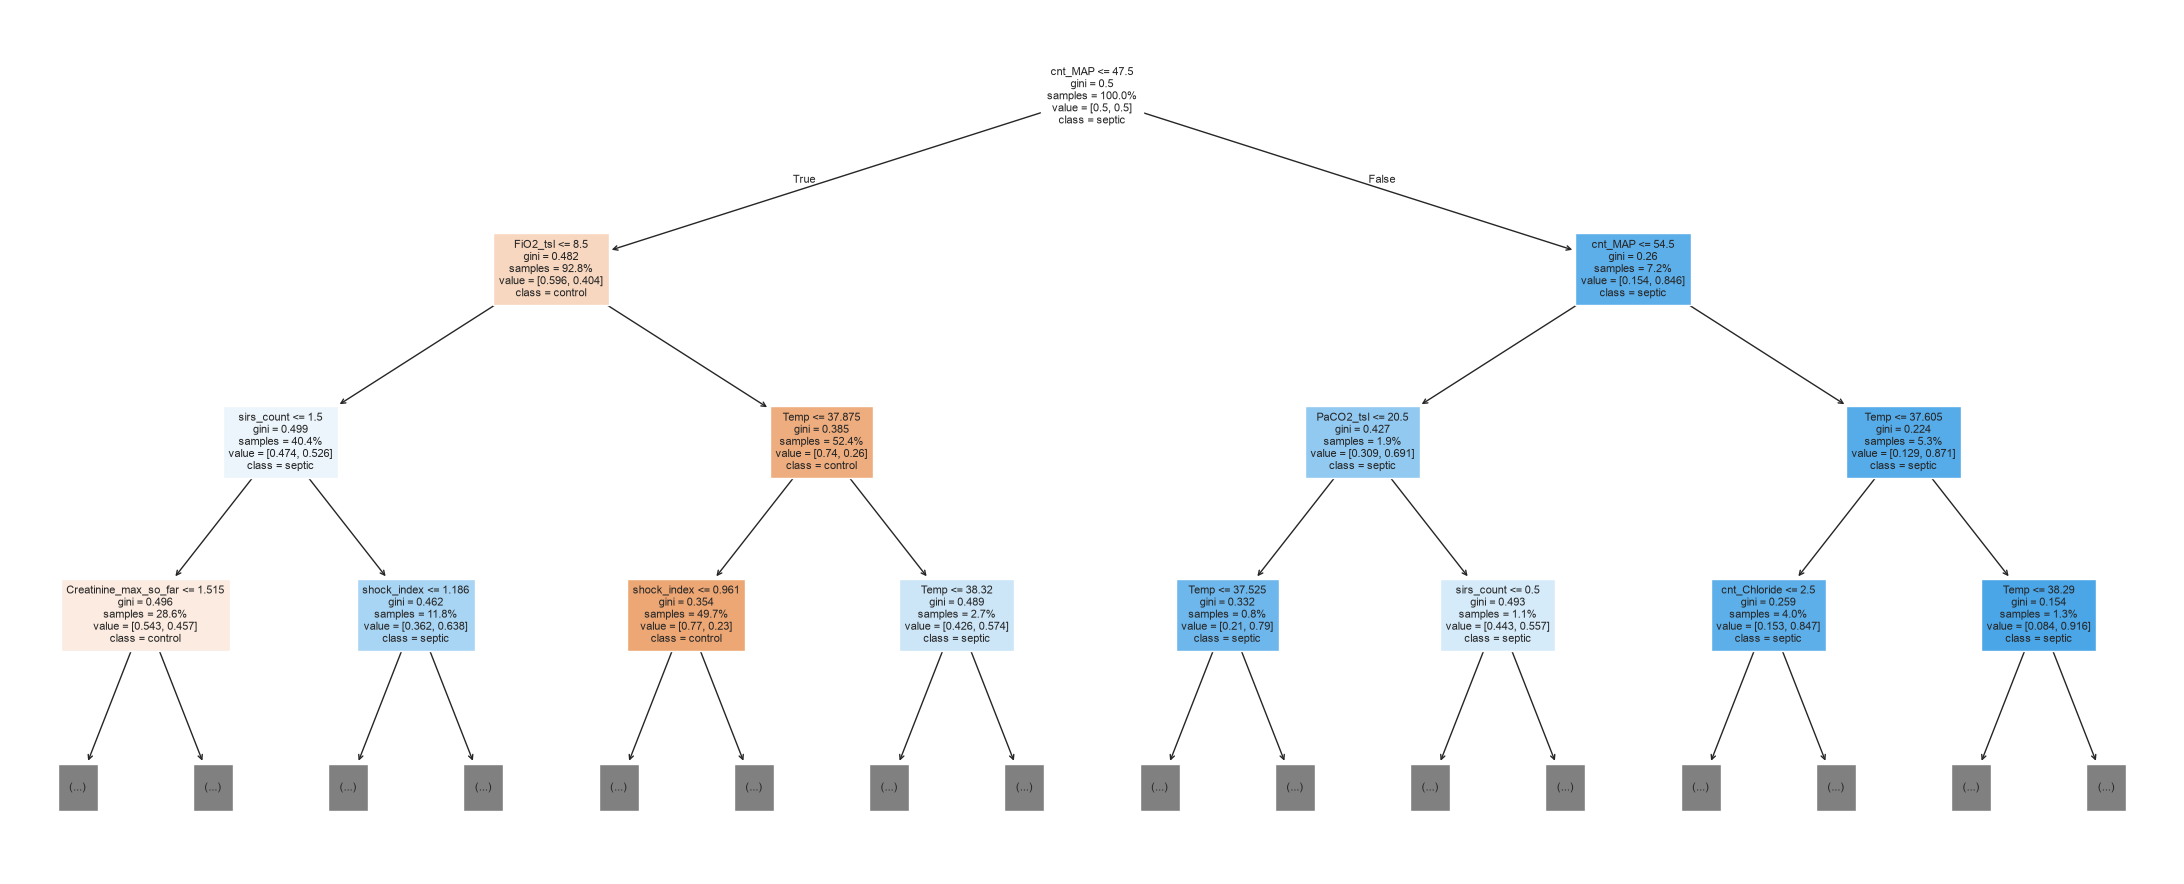

In [7]:
Xva_c = XC[va]
dt_keys = ["criterion", "max_depth", "min_samples_leaf", "class_weight"]
dt_grid = list(itertools.product(["gini", "entropy"], [4, 6, 8, 10, 12, 16], [50, 200, 500, 1000, 2000], [None, "balanced"]))
pick = np.random.default_rng(SEED).choice(len(dt_grid), 20, replace=False)
dt_cfgs = [dict(zip(dt_keys, dt_grid[i])) for i in pick]
dt_rows = []
with timed("dt tuning"):
    for cfg in tqdm(dt_cfgs, desc="dt"):
        m = DecisionTreeClassifier(**cfg, random_state=SEED).fit(X_tune, y_tune)
        p = m.predict_proba(Xva_c)[:, 1]
        dt_rows.append({**cfg, "val_auprc": average_precision_score(y_va, p), "val_auroc": roc_auc_score(y_va, p), "n_leaves": int(m.get_n_leaves())})
dt_tun = pd.DataFrame(dt_rows).sort_values("val_auprc", ascending=False)
put(dt_tun, "m2_dt_tuning.csv")
log(dt_tun.head(10).to_string(index=False))

ge = dt_tun.groupby("criterion")["val_auprc"].max().reindex(["gini", "entropy"]).reset_index(name="best_val_auprc")
put(ge, "m2_dt_gini_vs_entropy.csv")
log(ge.to_string(index=False))

best_dt = dt_cfgs[int(np.argmax([r["val_auprc"] for r in dt_rows]))]
msl = int(round(best_dt["min_samples_leaf"] * len(tr) / TUNE_ROWS))
log(f"best dt config {best_dt}, min_samples_leaf scaled to {msl} for all train rows")
Xc_tr = XC[tr]
with timed("dt refit"):
    dt = DecisionTreeClassifier(**{**best_dt, "min_samples_leaf": msl}, random_state=SEED).fit(Xc_tr, y_tr)
p = dt.predict_proba(Xva_c)[:, 1]
log(f"M2 best fit val auroc {roc_auc_score(y_va, p):.3f}, auprc {average_precision_score(y_va, p):.3f}, leaves {dt.get_n_leaves()}")

interp = DecisionTreeClassifier(criterion=best_dt["criterion"], max_depth=4, min_samples_leaf=2000, class_weight="balanced", random_state=SEED).fit(Xc_tr, y_tr)
p = interp.predict_proba(Xva_c)[:, 1]
log(f"interpretation tree val auroc {roc_auc_score(y_va, p):.3f}, auprc {average_precision_score(y_va, p):.3f}")
rules = export_text(interp, feature_names=CORE, max_depth=4)
(TAB / "m2_dt_rules.txt").write_text(rules)
SAVED.append(TAB / "m2_dt_rules.txt")
log("\n".join(rules.splitlines()[:40]))
del Xc_tr
gc.collect()

plt.figure(figsize=(22, 9))
plot_tree(interp, max_depth=3, feature_names=CORE, class_names=["control", "septic"], filled=True, proportion=True, fontsize=8)
save_fig("fig08_dt_interpretation_tree.png")

## M3, random forest

Ten random configurations are tuned on the tuning sample with the core matrix. The final forest and the all-feature forest use the same config and the same 600,000 rows.

rf: 100%|██████████| 10/10 [06:37<00:00, 39.76s/it]


rf tuning: 397.6 s
 max_depth  min_samples_leaf max_features  val_auprc  val_auroc  fit_s
        12               300        0.300      0.107      0.827 48.535
        12               300         sqrt      0.105      0.827 21.685
        20                50         sqrt      0.104      0.826 32.697
         8                20         sqrt      0.103      0.818 30.306
        12                50        0.300      0.102      0.822 58.279
         8                20        0.300      0.102      0.820 36.623
        16                50         sqrt      0.101      0.825 39.469
        12                50         sqrt      0.101      0.825 31.753
        20                20        0.300      0.098      0.818 69.298
        12                20         sqrt      0.098      0.816 28.902
best rf config {'max_depth': 12, 'min_samples_leaf': 300, 'max_features': 0.3}
rf final fit, core: 316.8 s
rf final fit, all features: 1125.6 s
M3 core val auroc 0.830, auprc 0.107
M3b all features va

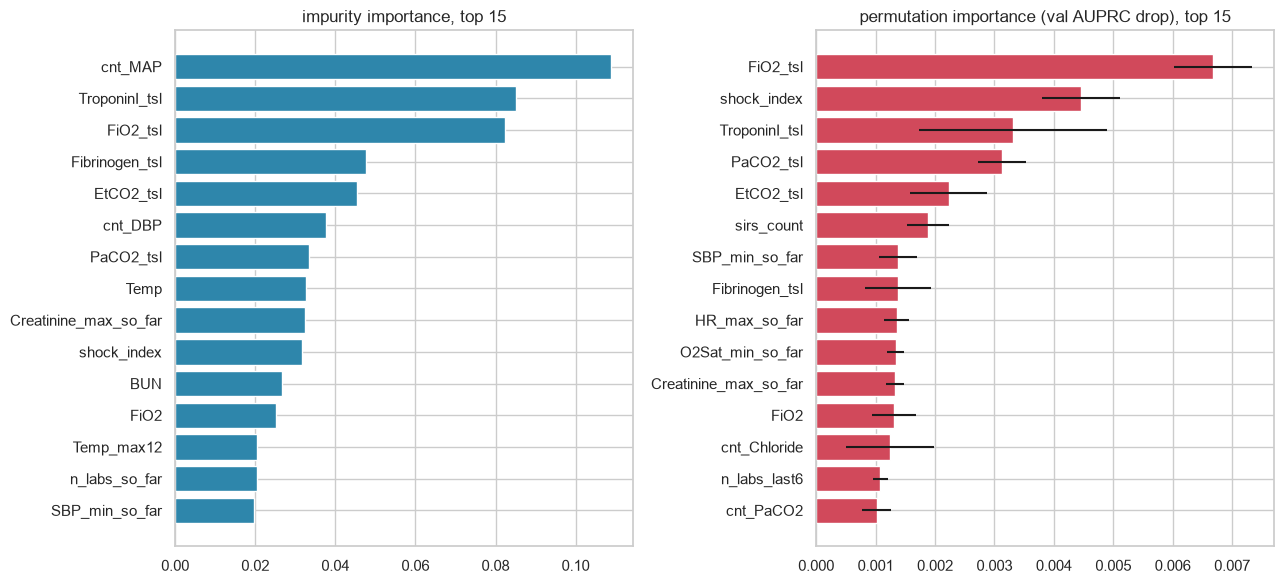

In [8]:
rf_keys = ["max_depth", "min_samples_leaf", "max_features"]
rf_grid = list(itertools.product([8, 12, 16, 20], [20, 50, 100, 300], ["sqrt", 0.3]))
pick = np.random.default_rng(SEED + 1).choice(len(rf_grid), 10, replace=False)
rf_cfgs = [dict(zip(rf_keys, rf_grid[i])) for i in pick]


def new_rf(cfg, n):
    return RandomForestClassifier(n_estimators=n, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED, **cfg)


rf_rows = []
with timed("rf tuning"):
    for cfg in tqdm(rf_cfgs, desc="rf"):
        t0 = time.time()
        m = new_rf(cfg, 100).fit(X_tune, y_tune)
        p = m.predict_proba(Xva_c)[:, 1]
        rf_rows.append({**cfg, "val_auprc": average_precision_score(y_va, p), "val_auroc": roc_auc_score(y_va, p), "fit_s": time.time() - t0})
        del m
rf_tun = pd.DataFrame(rf_rows).sort_values("val_auprc", ascending=False)
put(rf_tun, "m3_rf_tuning.csv")
log(rf_tun.to_string(index=False))
best_rf = rf_cfgs[int(np.argmax([r["val_auprc"] for r in rf_rows]))]
log(f"best rf config {best_rf}")
del X_tune
gc.collect()

with timed("rf final fit, core"):
    rf = new_rf(best_rf, 250).fit(X_fit_core, y_fit)
with timed("rf final fit, all features"):
    rf_all = new_rf(best_rf, 250).fit(XFA, y_fit)
p3, p3b = rf.predict_proba(Xva_c)[:, 1], rf_all.predict_proba(XVA)[:, 1]
log(f"M3 core val auroc {roc_auc_score(y_va, p3):.3f}, auprc {average_precision_score(y_va, p3):.3f}")
log(f"M3b all features val auroc {roc_auc_score(y_va, p3b):.3f}, auprc {average_precision_score(y_va, p3b):.3f}")
del X_fit_core, XFA, p3, p3b
gc.collect()

imp = pd.DataFrame({"feature": CORE, "importance": rf.feature_importances_}).sort_values("importance", ascending=False)
put(imp, "m3_rf_importance.csv")
pi_rows = np.sort(np.random.default_rng(SEED).choice(len(va), min(60_000, len(va)), replace=False))
with timed("permutation importance"):
    pi = permutation_importance(rf, Xva_c[pi_rows], y_va[pi_rows], scoring="average_precision", n_repeats=3, n_jobs=-1, random_state=SEED)
perm = pd.DataFrame({"feature": CORE, "mean": pi.importances_mean, "std": pi.importances_std}).sort_values("mean", ascending=False)
put(perm, "m3_rf_permutation.csv")
log("impurity importance, top 10:\n" + imp.head(10).to_string(index=False))
log("permutation importance, top 10:\n" + perm.head(10).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
t = imp.head(15).iloc[::-1]
ax[0].barh(t["feature"], t["importance"], color=COL_CONTROL)
ax[0].set_title("impurity importance, top 15")
t = perm.head(15).iloc[::-1]
ax[1].barh(t["feature"], t["mean"], xerr=t["std"], color=COL_SEPTIC)
ax[1].set_title("permutation importance (val AUPRC drop), top 15")
save_fig("fig08_rf_importance.png")

## Evaluation of M0 to M3b

Thresholds are chosen on val scores only and saved before the test rows are scored. Test is scored once at the end.

In [9]:
NAMES = ["M0_sirs", "M1_lr", "M2_dt", "M3_rf", "M3b_rf_all"]
NFEAT = {"M0_sirs": 1, "M1_lr": len(CORE), "M2_dt": len(CORE), "M3_rf": len(CORE), "M3b_rf_all": len(ALL)}
XA = {"val": XVA, "test": XTA}
TEST_SCORED = False


def score(name, which):
    ix = IDX[which]
    if name == "M0_sirs":
        s = sirs[ix]
    elif name == "M1_lr":
        s = lr.predict_proba(XS[ix])[:, 1]
    elif name == "M2_dt":
        s = dt.predict_proba(XC[ix])[:, 1]
    elif name == "M3_rf":
        s = rf.predict_proba(XC[ix])[:, 1]
    else:
        s = rf_all.predict_proba(XA[which])[:, 1]
    return np.asarray(s, dtype=np.float32)


S_VAL = {n: score(n, "val") for n in tqdm(NAMES, desc="val scores")}
THR = {"M0_sirs": 2.0}
for n in NAMES[1:]:
    THR[n] = ev.best_f2_threshold(y_va, S_VAL[n])
log("alert thresholds (chosen on val): " + ", ".join(f"{k}={v:.4f}" for k, v in THR.items()))
(PROC / "thresholds_m0_m3.json").write_text(json.dumps(THR, indent=2))
SAVED.append(PROC / "thresholds_m0_m3.json")
THR_SAVED_BEFORE_TEST = not TEST_SCORED
log(f"thresholds saved, test scored yet: {TEST_SCORED}")

val scores: 100%|██████████| 5/5 [00:02<00:00,  2.28it/s]

alert thresholds (chosen on val): M0_sirs=2.0000, M1_lr=0.7156, M2_dt=0.8017, M3_rf=0.6154, M3b_rf_all=0.6032
thresholds saved, test scored yet: False


In [10]:
def results_table(S, y, thr):
    rows = [{"model": n, "n_features": NFEAT[n], "threshold": thr[n], **ev.row_metrics(y, S[n], thr[n]), **ev.curve_metrics(y, S[n])} for n in NAMES]
    return pd.DataFrame(rows)


def alerts_table(S, m, thr):
    return pd.DataFrame([{"model": n, **ev.alert_metrics(m, S[n], thr[n])} for n in NAMES])


SHOW = ["model", "threshold", "sensitivity", "specificity", "precision", "f2", "auroc", "auprc"]
res_val = results_table(S_VAL, y_va, THR)
put(res_val, "m0_m3_results_val.csv")
log("note: the val threshold is tuned on val, so the val metrics are optimistic")
log(res_val[SHOW].to_string(index=False))

al_val = alerts_table(S_VAL, meta_val, THR)
put(al_val, "m0_m3_alert_metrics_val.csv")
log(al_val.to_string(index=False))

sweep_rows = []
for n in NAMES:
    s = S_VAL[n]
    th = np.array([1.0, 2.0, 3.0, 4.0]) if n == "M0_sirs" else np.unique(np.quantile(s, np.linspace(0.5, 0.99, 15)).astype(float))
    sw = ev.sweep_thresholds(y_va, s, th)[["threshold", "sensitivity", "specificity", "precision", "f1", "f2"]]
    ex = pd.DataFrame([ev.alert_metrics(meta_val, s, t) for t in tqdm(th, desc=f"sweep {n}")])
    sw["share_alerted_by_first_label"] = ex["share_alerted_by_first_label"].to_numpy()
    sw["false_alert_episodes_per_100_patient_days"] = ex["false_alert_episodes_per_100_patient_days"].to_numpy()
    sw.insert(0, "model", n)
    sweep_rows.append(sw)
sweep = pd.concat(sweep_rows, ignore_index=True)
put(sweep, "m0_m3_threshold_sweep_val.csv")
log("threshold sweep on val (rq3), first rows per model:\n" + sweep.groupby("model").head(3).to_string(index=False))

note: the val threshold is tuned on val, so the val metrics are optimistic
     model  threshold  sensitivity  specificity  precision    f2  auroc  auprc
   M0_sirs      2.000        0.522        0.706      0.031 0.126  0.650  0.031
     M1_lr      0.716        0.431        0.921      0.090 0.245  0.786  0.083
     M2_dt      0.802        0.369        0.944      0.108 0.248  0.787  0.086
     M3_rf      0.615        0.475        0.926      0.105 0.278  0.830  0.107
M3b_rf_all      0.603        0.453        0.934      0.111 0.281  0.841  0.115
     model  n_early  share_alerted_by_first_label  share_alerted_any  median_lead_h  median_timing_all_alerted_h  n_first_row  share_alerted_any_first_row  n_nonseptic  share_nonseptic_ever_alerted  false_alert_episodes_per_100_patient_days
   M0_sirs      375                         0.840              0.923         38.000                       33.000           65                        0.662         5610                         0.732             

sweep M3b_rf_all: 100%|██████████| 15/15 [00:01<00:00, 11.43it/s]

threshold sweep on val (rq3), first rows per model:
     model  threshold  sensitivity  specificity  precision    f1    f2  share_alerted_by_first_label  false_alert_episodes_per_100_patient_days
   M0_sirs      1.000        0.835        0.345      0.023 0.044 0.102                         0.965                                    323.126
   M0_sirs      2.000        0.522        0.706      0.031 0.059 0.126                         0.840                                    172.325
   M0_sirs      3.000        0.211        0.922      0.047 0.077 0.124                         0.568                                     52.357
     M1_lr      0.344        0.849        0.506      0.030 0.059 0.133                         0.987                                    245.780
     M1_lr      0.363        0.834        0.542      0.032 0.062 0.139                         0.981                                    231.206
     M1_lr      0.383        0.816        0.577      0.034 0.065 0.145              

test scores: 100%|██████████| 5/5 [00:02<00:00,  1.87it/s]


test scored once
     model  threshold  sensitivity  specificity  precision    f2  auroc  auprc
   M0_sirs      2.000        0.499        0.708      0.031 0.123  0.638  0.029
     M1_lr      0.716        0.409        0.925      0.091 0.241  0.787  0.098
     M2_dt      0.802        0.347        0.948      0.109 0.241  0.786  0.093
     M3_rf      0.615        0.447        0.931      0.107 0.273  0.833  0.108
M3b_rf_all      0.603        0.440        0.940      0.118 0.285  0.844  0.114
     model  n_early  share_alerted_by_first_label  share_alerted_any  median_lead_h  median_timing_all_alerted_h  n_first_row  share_alerted_any_first_row  n_nonseptic  share_nonseptic_ever_alerted  false_alert_episodes_per_100_patient_days
   M0_sirs      377                         0.828              0.923         36.500                       28.000           63                        0.698         5611                         0.730                                    172.729
     M1_lr      377        

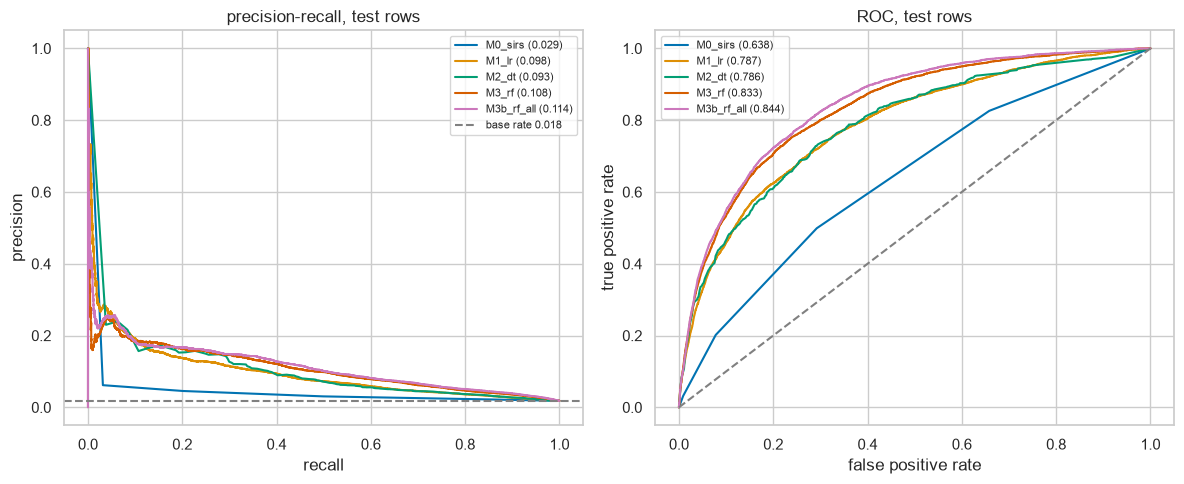

In [11]:
S_TE = {n: score(n, "test") for n in tqdm(NAMES, desc="test scores")}
TEST_SCORED = True
res_te = results_table(S_TE, y_te, THR)
al_te = alerts_table(S_TE, meta_test, THR)
put(res_te, "m0_m3_results_test.csv")
put(al_te, "m0_m3_alert_metrics_test.csv")
log("test scored once")
log(res_te[SHOW].to_string(index=False))
log(al_te.to_string(index=False))
log(f"accuracy of always predicting 0 on test: {1 - y_te.mean():.4f}")
log("model accuracies on test: " + ", ".join(f"{r.model}={r.accuracy:.4f}" for r in res_te.itertuples()))

for S, m, name in ((S_VAL, meta_val, "scores_m0_m3_val.parquet"), (S_TE, meta_test, "scores_m0_m3_test.parquet")):
    d = m[["patient_id", "hour", "SepsisLabel"]].copy()
    for n in NAMES:
        d[n] = S[n]
    d.to_parquet(PROC / name, index=False)
    SAVED.append(PROC / name)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for n, c in zip(NAMES, sns.color_palette("colorblind", len(NAMES))):
    pr, rc, _ = precision_recall_curve(y_te, S_TE[n])
    ax[0].plot(rc, pr, color=c, label=f"{n} ({res_te.set_index('model').loc[n, 'auprc']:.3f})")
    fpr, tpr, _ = roc_curve(y_te, S_TE[n])
    ax[1].plot(fpr, tpr, color=c, label=f"{n} ({res_te.set_index('model').loc[n, 'auroc']:.3f})")
ax[0].axhline(y_te.mean(), ls="--", color="grey", label=f"base rate {y_te.mean():.3f}")
ax[0].set(xlabel="recall", ylabel="precision", title="precision-recall, test rows")
ax[1].plot([0, 1], [0, 1], ls="--", color="grey")
ax[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC, test rows")
for a_ in ax:
    a_.legend(fontsize=8)
save_fig("fig08_pr_roc_test.png")

In [12]:
fails0 = COUNTS["fail"]
with guarded("scores finite and right length"):
    ok = all(bool(np.isfinite(S[n]).all()) and len(S[n]) == len(y) for S, y in ((S_VAL, y_va), (S_TE, y_te)) for n in NAMES)
    check("scores finite and of the right length", ok, f"{len(NAMES)} models, val and test")
with guarded("thresholds fixed before test"):
    saved = json.loads((PROC / "thresholds_m0_m3.json").read_text())
    check("thresholds fixed before test scoring", THR_SAVED_BEFORE_TEST and all(abs(saved[n] - THR[n]) < 1e-12 for n in NAMES), "json written before test scores")
with guarded("alert group sizes"):
    for tag, al, k in (("val", al_val, KNOWN["val"]), ("test", al_te, KNOWN["test"])):
        ok = bool(((al["n_early"] + al["n_first_row"]) == k["septic"]).all()) and bool((al["n_first_row"] == k["first_row"]).all()) \
            and bool((al["n_nonseptic"] == k["patients"] - k["septic"]).all())
        check(f"{tag} alert group sizes", ok, f"early + first-row {k['septic']}, first-row {k['first_row']}, never-septic {k['patients'] - k['septic']}")
with guarded("confusion matrix sums"):
    ok = bool(((res_val[["tp", "fp", "tn", "fn"]].sum(axis=1)) == len(y_va)).all()) and bool(((res_te[["tp", "fp", "tn", "fn"]].sum(axis=1)) == len(y_te)).all())
    check("confusion matrix sums equal row counts", ok, f"val {len(y_va)}, test {len(y_te)}")
with guarded("leakage guard"):
    top = max(res_val["auroc"].max(), res_te["auroc"].max())
    check("no model auroc above 0.95", top <= 0.95, f"max {top:.3f}")
with guarded("model structure"):
    check("rf has 250 trees", len(rf.estimators_) == 250 and len(rf_all.estimators_) == 250, f"{len(rf.estimators_)} and {len(rf_all.estimators_)}")
    check("interpretation tree depth at most 4", interp.get_depth() <= 4, f"depth {interp.get_depth()}")
    check("rf all-feature model uses 239 features", rf_all.n_features_in_ == len(ALL), f"{rf_all.n_features_in_}")

del rf_all, XA, XVA, XTA, S_VAL, S_TE
gc.collect()

[PASS] scores finite and of the right length (5 models, val and test)
[PASS] thresholds fixed before test scoring (json written before test scores)
[PASS] val alert group sizes (early + first-row 440, first-row 65, never-septic 5610)
[PASS] test alert group sizes (early + first-row 440, first-row 63, never-septic 5611)
[PASS] confusion matrix sums equal row counts (val 234037, test 232215)
[PASS] no model auroc above 0.95 (max 0.844)
[PASS] rf has 250 trees (250 and 250)
[PASS] interpretation tree depth at most 4 (depth 4)
[PASS] rf all-feature model uses 239 features (239)


7902

## Five-fold cross-validation

Folds come from cv_fold of the train and val patients, and each fold is scored on its held-out patients. The tree models use at most 500,000 random training rows per fold.

In [13]:
if RUN_CV:
    tv = split_arr != "test"
    fold_row = meta["patient_id"].map(splits.set_index("patient_id")["cv_fold"]).fillna(-9).to_numpy().astype(int)
    check("train and val rows all have a fold in 0..4", bool(np.isin(fold_row[tv], range(5)).all()), f"{int(tv.sum())} rows")
    cv_rows = []

    def cv_entry(model, f, y, s):
        return {"model": model, "fold": f, "auroc": roc_auc_score(y, s), "auprc": average_precision_score(y, s)}

    for f in range(5):
        t0 = time.time()
        held = np.flatnonzero(tv & (fold_row == f))
        trn = np.flatnonzero(tv & (fold_row != f))
        yh = y_all[held]
        cv_rows.append(cv_entry("M0_sirs", f, yh, sirs[held]))
        m = fit_quiet(LogisticRegression(C=best_C, class_weight="balanced", solver="lbfgs", max_iter=500, random_state=SEED), XS[trn], y_all[trn])
        cv_rows.append(cv_entry("M1_lr", f, yh, m.predict_proba(XS[held])[:, 1]))
        sub = np.sort(np.random.default_rng(SEED + f).choice(trn, min(CV_ROWS, len(trn)), replace=False))
        Xh, Xsub, ysub = XC[held], XC[sub], y_all[sub]
        msl_f = int(round(best_dt["min_samples_leaf"] * len(sub) / TUNE_ROWS))
        m = DecisionTreeClassifier(**{**best_dt, "min_samples_leaf": msl_f}, random_state=SEED).fit(Xsub, ysub)
        cv_rows.append(cv_entry("M2_dt", f, yh, m.predict_proba(Xh)[:, 1]))
        m = new_rf(best_rf, 100).fit(Xsub, ysub)
        cv_rows.append(cv_entry("M3_rf", f, yh, m.predict_proba(Xh)[:, 1]))
        del m, Xh, Xsub
        gc.collect()
        log(f"fold {f}: {len(held)} held-out rows, {len(sub)} tree training rows, {time.time() - t0:.1f} s")
    cv = pd.DataFrame(cv_rows)
    cv_sum = cv.groupby("model", sort=False).agg(auroc_mean=("auroc", "mean"), auroc_std=("auroc", "std"),
                                                  auprc_mean=("auprc", "mean"), auprc_std=("auprc", "std")).reset_index()
    put(cv, "m0_m3_cv_results.csv")
    put(cv_sum, "m0_m3_cv_summary.csv")
    log(cv_sum.to_string(index=False))
    log("note: the scaling parameters and the core-feature selection came from train rows, which include some held-out patients, so the CV scores may be slightly optimistic")
    with guarded("cv checks"):
        check("cv has 5 folds for each of 4 models", len(cv) == 20 and bool(np.isfinite(cv[["auroc", "auprc"]].to_numpy()).all()), f"{len(cv)} rows")
else:
    log("RUN_CV is False, cross-validation skipped")

[PASS] train and val rows all have a fold in 0..4 (1319995 rows)
fold 0: 262264 held-out rows, 500000 tree training rows, 84.8 s
fold 1: 265600 held-out rows, 500000 tree training rows, 81.5 s
fold 2: 265169 held-out rows, 500000 tree training rows, 43.3 s
fold 3: 263736 held-out rows, 500000 tree training rows, 45.4 s
fold 4: 263226 held-out rows, 500000 tree training rows, 46.3 s
  model  auroc_mean  auroc_std  auprc_mean  auprc_std
M0_sirs       0.641      0.009       0.030      0.001
  M1_lr       0.782      0.013       0.084      0.009
  M2_dt       0.774      0.009       0.082      0.004
  M3_rf       0.828      0.007       0.102      0.008
note: the scaling parameters and the core-feature selection came from train rows, which include some held-out patients, so the CV scores may be slightly optimistic
[PASS] cv has 5 folds for each of 4 models (20 rows)


## Output files

Every saved file is listed with its size, then the check count is printed and the log is written to results.

In [14]:
for p in SAVED:
    log(f"{p.relative_to(ROOT)}: " + (f"{p.stat().st_size / 1e6:.3f} MB" if p.exists() else "MISSING"))
missing = [p.name for p in SAVED if not p.exists()]
check("all saved files exist", not missing, f"{len(SAVED)} files" if not missing else f"missing {missing}")
log(f"lbfgs convergence warnings in total: {CONV['n']}")
log(f"checks: {COUNTS['pass']} passed, {COUNTS['fail']} failed")
out = ROOT / "results" / "step08_summary.txt"
out.write_text("\n".join(SUMMARY))
print(out)

results/tables/m1_lr_tuning.csv: 0.000 MB
results/tables/m1_lr_coefficients.csv: 0.001 MB
results/tables/m2_dt_tuning.csv: 0.001 MB
results/tables/m2_dt_gini_vs_entropy.csv: 0.000 MB
results/tables/m2_dt_rules.txt: 0.001 MB
results/figures/fig08_dt_interpretation_tree.png: 0.264 MB
results/tables/m3_rf_tuning.csv: 0.001 MB
results/tables/m3_rf_importance.csv: 0.002 MB
results/tables/m3_rf_permutation.csv: 0.003 MB
results/figures/fig08_rf_importance.png: 0.103 MB
data/processed/thresholds_m0_m3.json: 0.000 MB
results/tables/m0_m3_results_val.csv: 0.001 MB
results/tables/m0_m3_alert_metrics_val.csv: 0.001 MB
results/tables/m0_m3_threshold_sweep_val.csv: 0.010 MB
results/tables/m0_m3_results_test.csv: 0.001 MB
results/tables/m0_m3_alert_metrics_test.csv: 0.001 MB
data/processed/scores_m0_m3_val.parquet: 4.572 MB
data/processed/scores_m0_m3_test.parquet: 4.540 MB
results/figures/fig08_pr_roc_test.png: 0.153 MB
results/tables/m0_m3_cv_results.csv: 0.001 MB
results/tables/m0_m3_cv_summary.c